In [1]:
# ============================================================
# CELL 1: Environment Check
# ============================================================
import torch, transformers, sklearn, pandas as pd, numpy as np, sys

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("scikit-learn:", sklearn.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GB")

C:\Users\CH.SC.U4CSE23160\Final_Year_Project\bert_env\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.10.11
PyTorch: 2.6.0+cu126
Transformers: 5.15.1
scikit-learn: 1.7.2
CUDA available: True
GPU: NVIDIA GeForce RTX 3070
VRAM: 8.0 GB


In [2]:
# ============================================================
# CELL 2: Imports, Config, HF Token, Device Setup
# ============================================================
from pathlib import Path
import json, random, gc, warnings
import numpy as np, pandas as pd, torch, torch.nn as nn

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, classification_report,
    confusion_matrix, f1_score, cohen_kappa_score, matthews_corrcoef,
    log_loss, roc_auc_score, top_k_accuracy_score,
)
from sklearn.utils.class_weight import compute_class_weight

from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification, Trainer,
    TrainingArguments, EarlyStoppingCallback, set_seed,
)

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# HUGGING FACE TOKEN  (replace with your token)
# ------------------------------------------------------------

HF_TOKEN = os.getenv("HF_TOKEN")
# ------------------------------------------------------------
BASE_DIR = Path(r"C:/Users/CH.SC.U4CSE23160/Neural Project/IndicHallbench-Hallucinations-Benchmark")
DATA_PATH       = BASE_DIR / "data/annotations/final/final_annotations.csv"
RESPONSES_PATH  = BASE_DIR / "data/annotations/working/responses.json"
REFERENCES_PATH = BASE_DIR / "data/annotations/working/references.json"

# ------------------------------------------------------------
# OUTPUT DIRECTORY — renamed for mBERT
# ------------------------------------------------------------
OUTPUT_DIR = BASE_DIR / "results/mbert_full_dataset"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# MODEL — mBERT (bert-base-multilingual-cased)
# ------------------------------------------------------------
MODEL_NAME  = "google-bert/bert-base-multilingual-cased"
MAX_LENGTH  = 128
TRAIN_BATCH_SIZE = 32
EVAL_BATCH_SIZE  = 32
GRADIENT_ACCUMULATION_STEPS = 1
EPOCHS = 15
LEARNING_RATE = 2e-5
WEIGHT_DECAY  = 0.01
WARMUP_RATIO  = 0.1
MAX_GRAD_NORM = 1.0
SEED = 42

set_seed(SEED); random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, "| Model:", MODEL_NAME, "| Output:", OUTPUT_DIR)

Device: cuda | Model: google-bert/bert-base-multilingual-cased | Output: C:\Users\CH.SC.U4CSE23160\Neural Project\IndicHallbench-Hallucinations-Benchmark\results\mbert_full_dataset


In [3]:
# ============================================================
# CELL 3: Load Raw Data and Inspect
# ============================================================
responses_df   = pd.read_json(RESPONSES_PATH)
references_df  = pd.read_json(REFERENCES_PATH)
annotations_df = pd.read_csv(DATA_PATH)

print("responses:  ", responses_df.shape)
print("references: ", references_df.shape)
print("annotations:", annotations_df.shape)

print("\nLanguage distribution in responses:")
print(responses_df["language"].value_counts())
print("\nModel distribution in responses:")
print(responses_df["model_name"].value_counts())
print("\nAnnotation correctness_label:")
print(annotations_df["correctness_label"].value_counts(dropna=False))

responses:   (64800, 10)
references:  (10800, 11)
annotations: (64800, 20)

Language distribution in responses:
language
EN       10800
HI       10800
HI-EN    10800
NE       10800
TA       10800
TE       10800
Name: count, dtype: int64

Model distribution in responses:
model_name
GPT-5.6 Luna           10800
Claude Sonnet 5.5      10800
DeepSeek-V4.1-Flash    10800
Gemini 3               10800
Qwen 3.7               10800
GLM-5.3 Flash          10800
Name: count, dtype: int64

Annotation correctness_label:
correctness_label
Correct              39459
Incorrect            13092
Partially Correct    12249
Name: count, dtype: int64


In [4]:
# ============================================================
# CELL 4: Merge DataFrames with Validation
# ============================================================
for df in [responses_df, references_df, annotations_df]:
    if "question_id" in df.columns:
        df["question_id"] = df["question_id"].astype("string").str.strip()
    if "language" in df.columns:
        df["language"] = df["language"].astype("string").str.strip().str.upper()
    if "model_name" in df.columns:
        df["model_name"] = df["model_name"].astype("string").str.strip()

LANGUAGE_ALIASES = {"HIEN": "HI-EN", "HI_EN": "HI-EN", "HINGLISH": "HI-EN"}
for df in [responses_df, annotations_df]:
    df["language"] = df["language"].replace(LANGUAGE_ALIASES)

assert references_df["question_id"].is_unique, "references has duplicate question_id!"

KEYS = ["question_id", "language", "model_name"]
assert not responses_df.duplicated(KEYS).any(), "responses has duplicate keys"
assert not annotations_df.duplicated(KEYS).any(), "annotations has duplicate keys"

refs_slim = references_df.drop(
    columns=["fact_id", "domain", "difficulty", "source_url"], errors="ignore"
)

merged = responses_df.merge(
    refs_slim,
    on="question_id",
    how="left",
    validate="many_to_one",
    suffixes=("_resp", "_ref"),
    indicator=True,
)
print("Responses ↔ References match:")
print(merged["_merge"].value_counts())
if (merged["_merge"] != "both").any():
    raise ValueError("Some responses have no reference match!")
merged.drop(columns="_merge", inplace=True)

ann_slim = annotations_df[KEYS + [
    "response_id", "correctness_label", "hallucination_types",
    "severity", "confidence", "judge_model",
]].copy()

merged = merged.merge(
    ann_slim,
    on=KEYS,
    how="left",
    validate="one_to_one",
    indicator=True,
)
print("\nMerged ↔ Annotations match:")
print(merged["_merge"].value_counts())
if (merged["_merge"] != "both").any():
    raise ValueError("Some rows have no annotation.")
merged.drop(columns="_merge", inplace=True)

print("\nFinal merged rows:", len(merged))
print("Missing correctness_label:", merged["correctness_label"].isna().sum())
print("\ncorrectness_label distribution:")
print(merged["correctness_label"].value_counts(dropna=False))
print("\nColumns:", merged.columns.tolist())

Responses ↔ References match:
_merge
both          64800
left_only         0
right_only        0
Name: count, dtype: int64

Merged ↔ Annotations match:
_merge
both          64800
left_only         0
right_only        0
Name: count, dtype: int64

Final merged rows: 64800
Missing correctness_label: 0

correctness_label distribution:
correctness_label
Correct              39459
Incorrect            13092
Partially Correct    12249
Name: count, dtype: int64

Columns: ['question_id', 'fact_id', 'domain', 'difficulty', 'fact_type', 'language', 'model_name', 'response', 'timestamp', 'source_url', 'question_type', 'question', 'ground_truth', 'answer_type', 'answer_length_category', 'primary_hallucination_type', 'response_id', 'correctness_label', 'hallucination_types', 'severity', 'confidence', 'judge_model']


In [5]:
# ============================================================
# CELL 5: Text Cleaning, Label Encoding, Input Construction
# ============================================================
for col in ["question", "ground_truth", "response"]:
    merged[col] = merged[col].fillna("").astype(str).str.strip()

before = len(merged)
merged = merged[
    (merged["question"] != "") &
    (merged["ground_truth"] != "") &
    (merged["response"] != "")
].copy()
print(f"Removed {before - len(merged)} rows with empty text.")

LABEL_FIX = {
    "correct": "Correct",
    "incorrect": "Incorrect",
    "partially correct": "Partially Correct",
    "partial": "Partially Correct",
    "uncertain": "Uncertain",
}
merged["correctness_label"] = (
    merged["correctness_label"].astype("string").str.strip().replace(LABEL_FIX)
)

VALID_LABELS = ["Correct", "Partially Correct", "Incorrect", "Uncertain"]
bad = sorted(set(merged["correctness_label"].dropna()) - set(VALID_LABELS))
if bad:
    raise ValueError(f"Unexpected labels: {bad}")

merged = merged.dropna(subset=["correctness_label"]).copy()
print("Final rows:", len(merged))
print("\nLabel distribution:")
print(merged["correctness_label"].value_counts())

def build_input(row):
    return (
        f"Question: {row['question']}\n"
        f"Ground Truth: {row['ground_truth']}\n"
        f"Model Response: {row['response']}"
    )

merged["input_text"] = merged.apply(build_input, axis=1)

label_encoder = LabelEncoder()
merged["label"] = label_encoder.fit_transform(merged["correctness_label"])
LABELS     = list(label_encoder.classes_)
NUM_LABELS = len(LABELS)

print("\nLabel mapping:")
for i, lbl in enumerate(LABELS):
    print(f"  {i} = {lbl}")

Removed 0 rows with empty text.
Final rows: 64800

Label distribution:
correctness_label
Correct              39459
Incorrect            13092
Partially Correct    12249
Name: count, dtype: Int64

Label mapping:
  0 = Correct
  1 = Incorrect
  2 = Partially Correct


In [6]:
# ============================================================
# CELL 6: Stratified Group Splits (Train/Dev/Test)
# ============================================================
def pick_fact_id_col(df):
    for candidate in ["fact_id", "fact_id_resp", "fact_id_ref",
                      "fact_id_response", "fact_id_reference"]:
        if candidate in df.columns:
            return candidate
    return None

fact_col = pick_fact_id_col(merged)
if fact_col is None:
    print("No fact_id column found — falling back to question_id as split group.")
    merged["split_group"] = "QUESTION_" + merged["question_id"].astype(str)
else:
    fact_ids = merged[fact_col].astype(str).str.strip()
    invalid_mask = fact_ids.isin(["", "nan", "None", "<NA>"]) | merged[fact_col].isna()
    merged["split_group"] = np.where(
        ~invalid_mask,
        "FACT_" + fact_ids,
        "QUESTION_" + merged["question_id"].astype(str),
    )

print("Unique split groups:", merged["split_group"].nunique())
print("Unique facts in responses:", merged["split_group"].str.startswith("FACT_").sum(),
      "rows |", merged.loc[merged["split_group"].str.startswith("FACT_"),
                           "split_group"].nunique(), "unique facts")

sgkf_test = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED)
folds = list(sgkf_test.split(
    merged["input_text"], merged["label"], groups=merged["split_group"]
))
test_pos      = np.concatenate([folds[i][1] for i in range(3)])
remaining_idx = np.setdiff1d(np.arange(len(merged)), test_pos)

remaining = merged.iloc[remaining_idx].reset_index(drop=True)
test_df   = merged.iloc[test_pos].reset_index(drop=True).copy()

sgkf_dev = StratifiedGroupKFold(n_splits=17, shuffle=True, random_state=SEED + 1)
dev_folds = list(sgkf_dev.split(
    remaining["input_text"], remaining["label"], groups=remaining["split_group"]
))
dev_pos = np.concatenate([dev_folds[i][1] for i in range(3)])

dev_df   = remaining.iloc[dev_pos].reset_index(drop=True).copy()
train_df = remaining.drop(index=remaining.index[dev_pos]).reset_index(drop=True).copy()

assert set(train_df["split_group"]).isdisjoint(set(dev_df["split_group"])), "Leakage: train ∩ dev"
assert set(train_df["split_group"]).isdisjoint(set(test_df["split_group"])), "Leakage: train ∩ test"
assert set(dev_df["split_group"]).isdisjoint(set(test_df["split_group"])), "Leakage: dev ∩ test"

total = len(merged)
print(f"\nTrain: {len(train_df):>6,} ({len(train_df)/total*100:.2f}%)")
print(f"Dev:   {len(dev_df):>6,} ({len(dev_df)/total*100:.2f}%)")
print(f"Test:  {len(test_df):>6,} ({len(test_df)/total*100:.2f}%)")
print("Group leakage check: PASSED")

print("\nClass distribution per split (%):")
for name, part in [("Train", train_df), ("Dev", dev_df), ("Test", test_df)]:
    vc = part["correctness_label"].value_counts(normalize=True).mul(100).round(2)
    print(f"  {name:5s}: {dict(vc)}")

Unique split groups: 10800
Unique facts in responses: 10800 rows | 1800 unique facts

Train: 45,360 (70.00%)
Dev:    9,720 (15.00%)
Test:   9,720 (15.00%)
Group leakage check: PASSED

Class distribution per split (%):
  Train: {'Correct': np.float64(61.29), 'Incorrect': np.float64(19.98), 'Partially Correct': np.float64(18.73)}
  Dev  : {'Correct': np.float64(59.43), 'Incorrect': np.float64(21.07), 'Partially Correct': np.float64(19.5)}
  Test : {'Correct': np.float64(60.51), 'Incorrect': np.float64(20.39), 'Partially Correct': np.float64(19.09)}


In [7]:
# ============================================================
# CELL 7: Compute Class Weights
# ============================================================
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(NUM_LABELS),
    y=train_df["label"].to_numpy(),
)
class_weights = torch.tensor(class_weights, dtype=torch.float).to(DEVICE)

print("Class weights (inverse frequency):")
for i, w in enumerate(class_weights.cpu().numpy()):
    print(f"  {LABELS[i]:20s}  ->  {w:.3f}")

Class weights (inverse frequency):
  Correct               ->  0.544
  Incorrect             ->  1.669
  Partially Correct     ->  1.779


In [8]:
# ============================================================
# CELL 8: Tokenizer + Dataset (mBERT with HF_TOKEN)
# ============================================================
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, token=HF_TOKEN)

class HallucinationDataset(torch.utils.data.Dataset):
    def __init__(self, df):
        self.enc = tokenizer(
            df["input_text"].tolist(),
            truncation=True, 
            padding="max_length",
            max_length=MAX_LENGTH, return_tensors="pt",
        )
        self.labels = df["label"].tolist()

    def __len__(self): return len(self.labels)

    def __getitem__(self, idx):
        item = {k: v[idx] for k, v in self.enc.items()}
        item["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

train_dataset = HallucinationDataset(train_df)
dev_dataset   = HallucinationDataset(dev_df)
test_dataset  = HallucinationDataset(test_df)

print(f"Train: {len(train_dataset):,} | Dev: {len(dev_dataset):,} | Test: {len(test_dataset):,}")

Train: 45,360 | Dev: 9,720 | Test: 9,720


In [9]:
# ============================================================
# CELL 9: Model + Weighted Trainer (mBERT with HF_TOKEN)
# ============================================================
class WeightedTrainer(Trainer):
    """Trainer with class-balanced cross-entropy loss."""
    def __init__(self, class_weights=None, **kwargs):
        super().__init__(**kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kw):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits  = outputs.logits
        loss = nn.CrossEntropyLoss(weight=self.class_weights)(
            logits.view(-1, model.config.num_labels), labels.view(-1)
        )
        return (loss, outputs) if return_outputs else loss


id2label = {i: l for i, l in enumerate(LABELS)}
label2id = {l: i for i, l in enumerate(LABELS)}

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_LABELS,
    id2label=id2label,
    label2id=label2id,
    token=HF_TOKEN,
).to(DEVICE)
print("Model loaded.")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 7968.79it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because mi

Model loaded.


In [10]:
# ============================================================
# CELL 10: Compute Metrics Function
# ============================================================
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    probs = torch.softmax(torch.tensor(logits), dim=-1).numpy()
    preds = np.argmax(logits, axis=-1)

    p, r, mf1, _ = precision_recall_fscore_support(labels, preds,
                                                   average="macro", zero_division=0)
    wf1 = f1_score(labels, preds, average="weighted", zero_division=0)

    def safe(fn):
        try: return fn()
        except Exception: return float("nan")

    return {
        "accuracy":        accuracy_score(labels, preds),
        "macro_precision": p,
        "macro_recall":    r,
        "macro_f1":        mf1,
        "weighted_f1":     wf1,
        "cohen_kappa":     safe(lambda: cohen_kappa_score(labels, preds)),
        "mcc":             safe(lambda: matthews_corrcoef(labels, preds)),
        "log_loss":        safe(lambda: log_loss(labels, probs,
                                                labels=list(range(NUM_LABELS)))),
        "roc_auc_macro":   safe(lambda: roc_auc_score(
            labels, probs, multi_class="ovr", average="macro",
            labels=list(range(NUM_LABELS)))),
        "top2_accuracy":   safe(lambda: top_k_accuracy_score(
            labels, probs, k=min(2, NUM_LABELS),
            labels=list(range(NUM_LABELS)))),
    }

In [11]:
# ============================================================
# CELL 11: Training Arguments + Trainer Setup
# ============================================================
from transformers import DataCollatorWithPadding
steps_per_epoch = int(np.ceil(
    len(train_dataset) / (TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS)
))
total_steps  = steps_per_epoch * EPOCHS
warmup_steps = int(total_steps * WARMUP_RATIO)
print(f"Steps/epoch: {steps_per_epoch} | Total: {total_steps} | Warmup: {warmup_steps}")

training_args = TrainingArguments(
    output_dir=str(OUTPUT_DIR / "checkpoints"),
    num_train_epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    warmup_steps=warmup_steps,
    max_grad_norm=MAX_GRAD_NORM,

    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,

    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=3,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,

    logging_strategy="steps",
    logging_steps=50,
    logging_first_step=True,
    disable_tqdm=False,

    fp16=torch.cuda.is_available(),
    dataloader_num_workers=0,

    report_to="none",
    seed=SEED, data_seed=SEED,
)

trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=dev_dataset,
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer, padding="longest"),
    compute_metrics=compute_metrics,
    class_weights=class_weights,
    callbacks=[
        EarlyStoppingCallback(early_stopping_patience=3),
    ],
)
print("Trainer ready.")

Steps/epoch: 1418 | Total: 21270 | Warmup: 2127
Trainer ready.


In [12]:
# ============================================================
# CELL 12: Train the Model
# ============================================================
train_result = trainer.train()
print("\nTraining done:", train_result.metrics)
trainer.save_model(OUTPUT_DIR / "best_model")
tokenizer.save_pretrained(OUTPUT_DIR / "best_model")

Epoch,Training Loss,Validation Loss,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Cohen Kappa,Mcc,Log Loss,Roc Auc Macro,Top2 Accuracy,Runtime,Samples Per Second,Steps Per Second
1,0.689487,0.731403,0.709568,0.663712,0.699373,0.672158,0.721187,0.520623,0.529704,0.673111,0.868885,0.910597,12.319800,788.974000,24.676000
2,0.593676,0.704183,0.705967,0.661357,0.715174,0.673011,0.717391,0.526498,0.541811,0.710468,0.884907,0.916255,12.330900,788.262000,24.653000
3,0.498272,0.692246,0.752160,0.711778,0.726821,0.711135,0.760046,0.578597,0.584372,0.603947,0.894723,0.938477,12.277000,791.726000,24.762000
4,0.431887,0.792594,0.752984,0.698242,0.731694,0.710961,0.759937,0.582829,0.587091,0.697265,0.895665,0.932819,12.798800,759.446000,23.752000
5,0.395200,0.858754,0.764198,0.710867,0.706990,0.708441,0.764609,0.581494,0.581689,0.649759,0.892937,0.940123,12.700400,765.329000,23.936000
6,0.303931,0.827609,0.749691,0.714264,0.737099,0.713559,0.760386,0.582035,0.592037,0.729031,0.896644,0.943621,12.640100,768.979000,24.050000
7,0.241563,0.999377,0.758848,0.711652,0.735391,0.716636,0.766740,0.591758,0.597387,0.840296,0.890092,0.942593,12.428800,782.055000,24.459000
8,0.231479,1.173600,0.769959,0.718023,0.716840,0.716879,0.770954,0.593157,0.593384,0.888898,0.892743,0.940741,12.310000,789.603000,24.695000
9,0.198048,1.244479,0.765329,0.718353,0.716831,0.714433,0.768203,0.588111,0.589525,0.957488,0.891099,0.936728,12.657200,767.940000,24.018000
10,0.157712,1.343759,0.771193,0.719220,0.721840,0.720212,0.772569,0.596788,0.596955,1.030046,0.894430,0.947531,12.823500,757.982000,23.706000


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.33it/s]
[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'ber


Training done: {'train_runtime': 3584.1703, 'train_samples_per_second': 189.835, 'train_steps_per_second': 5.934, 'total_flos': 4.47555923555328e+16, 'train_loss': 0.28963635248032654, 'epoch': 15.0}


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.93it/s]


('C:\\Users\\CH.SC.U4CSE23160\\Neural Project\\IndicHallbench-Hallucinations-Benchmark\\results\\mbert_full_dataset\\best_model\\tokenizer_config.json',
 'C:\\Users\\CH.SC.U4CSE23160\\Neural Project\\IndicHallbench-Hallucinations-Benchmark\\results\\mbert_full_dataset\\best_model\\tokenizer.json')

In [13]:

# ============================================================
# CELL 13: COMPREHENSIVE TEST SET EVALUATION
# HUGGING FACE TRAINER
# ============================================================

# ------------------------------------------------------------
# 1. Import required libraries
# ------------------------------------------------------------

import numpy as np
import torch
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    cohen_kappa_score,
    matthews_corrcoef,
    roc_auc_score,
    log_loss,
    top_k_accuracy_score,
    balanced_accuracy_score
)

# ------------------------------------------------------------
# 2. Generate predictions
# ------------------------------------------------------------

test_results = trainer.predict(test_dataset)

test_logits = np.asarray(test_results.predictions)
test_true = np.asarray(test_results.label_ids)

# Handle models returning tuple predictions
if test_logits.ndim != 2:
    raise ValueError(
        f"Expected 2D classification logits, got shape {test_logits.shape}"
    )

test_probs = torch.softmax(
    torch.as_tensor(test_logits, dtype=torch.float32),
    dim=-1
).cpu().numpy()

test_preds = np.argmax(test_logits, axis=1)

class_labels = list(range(NUM_LABELS))

# ------------------------------------------------------------
# 3. Classification report
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TEST SET CLASSIFICATION REPORT")
print("=" * 70)

print(classification_report(
    test_true,
    test_preds,
    labels=class_labels,
    target_names=LABELS,
    digits=4,
    zero_division=0
))

# ------------------------------------------------------------
# 4. Classification metrics
# ------------------------------------------------------------

# Accuracy
test_acc = accuracy_score(test_true, test_preds)

# Precision
test_precision_macro = precision_score(
    test_true,
    test_preds,
    average="macro",
    zero_division=0
)

test_precision_weighted = precision_score(
    test_true,
    test_preds,
    average="weighted",
    zero_division=0
)

# Recall
test_recall_macro = recall_score(
    test_true,
    test_preds,
    average="macro",
    zero_division=0
)

test_recall_weighted = recall_score(
    test_true,
    test_preds,
    average="weighted",
    zero_division=0
)

# F1-score
test_mf1 = f1_score(
    test_true,
    test_preds,
    average="macro",
    zero_division=0
)

test_wf1 = f1_score(
    test_true,
    test_preds,
    average="weighted",
    zero_division=0
)

# Balanced Accuracy
test_bal_acc = balanced_accuracy_score(
    test_true,
    test_preds
)

# Agreement metrics
test_kap = cohen_kappa_score(
    test_true,
    test_preds
)

test_mcc = matthews_corrcoef(
    test_true,
    test_preds
)

# ------------------------------------------------------------
# 5. ROC-AUC
# ------------------------------------------------------------

try:
    if NUM_LABELS == 2:
        test_auc = roc_auc_score(
            test_true,
            test_probs[:, 1]
        )
    else:
        test_auc = roc_auc_score(
            test_true,
            test_probs,
            multi_class="ovr",
            average="macro",
            labels=class_labels
        )

except ValueError as e:
    print("ROC-AUC warning:", e)
    test_auc = float("nan")

# ------------------------------------------------------------
# 6. Log Loss
# ------------------------------------------------------------

try:
    test_ll = log_loss(
        test_true,
        test_probs,
        labels=class_labels
    )

except ValueError as e:
    print("Log Loss warning:", e)
    test_ll = float("nan")

# ------------------------------------------------------------
# 7. Top-2 Accuracy
# ------------------------------------------------------------

try:
    test_top2 = top_k_accuracy_score(
        test_true,
        test_probs,
        k=min(2, NUM_LABELS),
        labels=class_labels
    )

except ValueError as e:
    print("Top-2 Accuracy warning:", e)
    test_top2 = float("nan")

# ------------------------------------------------------------
# 8. Print complete evaluation results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL TEST SET PERFORMANCE")
print("=" * 70)

print(f"Accuracy:             {test_acc:.4f}")
print(f"Macro Precision:      {test_precision_macro:.4f}")
print(f"Weighted Precision:   {test_precision_weighted:.4f}")
print(f"Macro Recall:         {test_recall_macro:.4f}")
print(f"Weighted Recall:      {test_recall_weighted:.4f}")
print(f"Macro F1:             {test_mf1:.4f}")
print(f"Weighted F1:          {test_wf1:.4f}")
print(f"Balanced Accuracy:    {test_bal_acc:.4f}")
print(f"Cohen's Kappa:        {test_kap:.4f}")
print(f"MCC:                  {test_mcc:.4f}")
print(f"ROC-AUC (Macro):      {test_auc:.4f}")
print(f"Log Loss:             {test_ll:.4f}")
print(f"Top-2 Accuracy:       {test_top2:.4f}")

# ------------------------------------------------------------
# 9. Store metrics in a DataFrame
# ------------------------------------------------------------

test_metrics_dict = {
    "Accuracy": test_acc,
    "Macro Precision": test_precision_macro,
    "Weighted Precision": test_precision_weighted,
    "Macro Recall": test_recall_macro,
    "Weighted Recall": test_recall_weighted,
    "Macro F1": test_mf1,
    "Weighted F1": test_wf1,
    "Balanced Accuracy": test_bal_acc,
    "Cohen's Kappa": test_kap,
    "MCC": test_mcc,
    "ROC-AUC (Macro)": test_auc,
    "Log Loss": test_ll,
    "Top-2 Accuracy": test_top2
}

test_metrics_df = pd.DataFrame(
    [test_metrics_dict]
)

display(test_metrics_df.round(4))

# ------------------------------------------------------------
# 10. Export evaluation metrics
# ------------------------------------------------------------

test_metrics_df.to_csv(
    "test_set_evaluation_metrics.csv",
    index=False
)

print("\nEvaluation completed successfully.")
print("Saved: test_set_evaluation_metrics.csv")


TEST SET CLASSIFICATION REPORT
                   precision    recall  f1-score   support

          Correct     0.8572    0.8767    0.8669      5882
        Incorrect     0.7514    0.6266    0.6834      1982
Partially Correct     0.5690    0.6288    0.5974      1856

         accuracy                         0.7784      9720
        macro avg     0.7259    0.7107    0.7159      9720
     weighted avg     0.7806    0.7784    0.7780      9720


FINAL TEST SET PERFORMANCE
Accuracy:             0.7784
Macro Precision:      0.7259
Weighted Precision:   0.7806
Macro Recall:         0.7107
Weighted Recall:      0.7784
Macro F1:             0.7159
Weighted F1:          0.7780
Balanced Accuracy:    0.7107
Cohen's Kappa:        0.5974
MCC:                  0.5984
ROC-AUC (Macro):      0.8831
Log Loss:             1.2120
Top-2 Accuracy:       0.9387


,Accuracy,Macro Precision,Weighted Precision,Macro Recall,Weighted Recall,Macro F1,Weighted F1,Balanced Accuracy,Cohen's Kappa,MCC,ROC-AUC (Macro),Log Loss,Top-2 Accuracy
0,0.7784,0.7259,0.7806,0.7107,0.7784,0.7159,0.778,0.7107,0.5974,0.5984,0.8831,1.212,0.9387



Evaluation completed successfully.
Saved: test_set_evaluation_metrics.csv


In [14]:
# ============================================================
# CELL 14: Per-Class Metrics
# ============================================================
p, r, f, sup = precision_recall_fscore_support(
    test_true, test_preds, labels=list(range(NUM_LABELS)), zero_division=0
)
per_class = pd.DataFrame({
    "label": LABELS, "precision": p, "recall": r, "f1": f, "support": sup,
})
print(per_class.round(4))
per_class.to_csv(OUTPUT_DIR / "per_class_metrics.csv", index=False)

               label  precision  recall      f1  support
0            Correct     0.8572  0.8767  0.8669     5882
1          Incorrect     0.7514  0.6266  0.6834     1982
2  Partially Correct     0.5690  0.6288  0.5974     1856


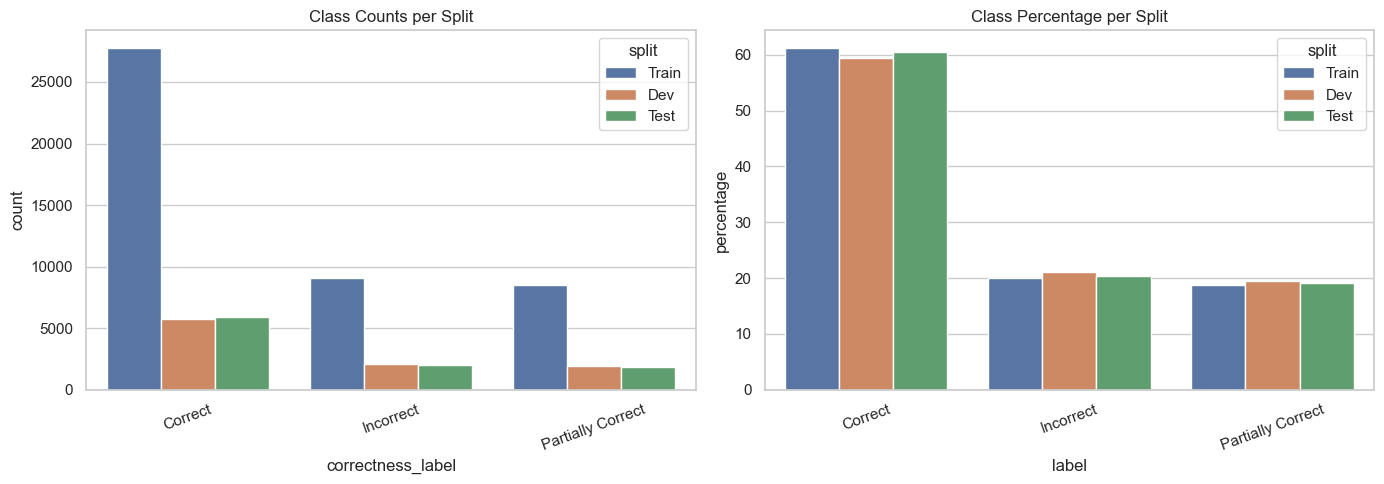

In [15]:
# ============================================================
# CELL 15: Split Distribution Visualization
# ============================================================
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

records = []
for name, part in [("Train", train_df), ("Dev", dev_df), ("Test", test_df)]:
    vc = part["correctness_label"].value_counts()
    for lbl in LABELS:
        records.append({
            "split": name, "label": lbl,
            "count": int(vc.get(lbl, 0)),
            "percentage": vc.get(lbl, 0) / len(part) * 100,
        })
split_dist = pd.DataFrame(records)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
combined = pd.concat([
    train_df.assign(split="Train"),
    dev_df.assign(split="Dev"),
    test_df.assign(split="Test"),
])
sns.countplot(data=combined, x="correctness_label", hue="split",
              order=LABELS, ax=axes[0])
axes[0].set_title("Class Counts per Split")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(data=split_dist, x="label", y="percentage", hue="split",
            order=LABELS, ax=axes[1])
axes[1].set_title("Class Percentage per Split")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "split_distribution.png", dpi=300, bbox_inches="tight")
plt.show()
split_dist.to_csv(OUTPUT_DIR / "split_class_distribution.csv", index=False)

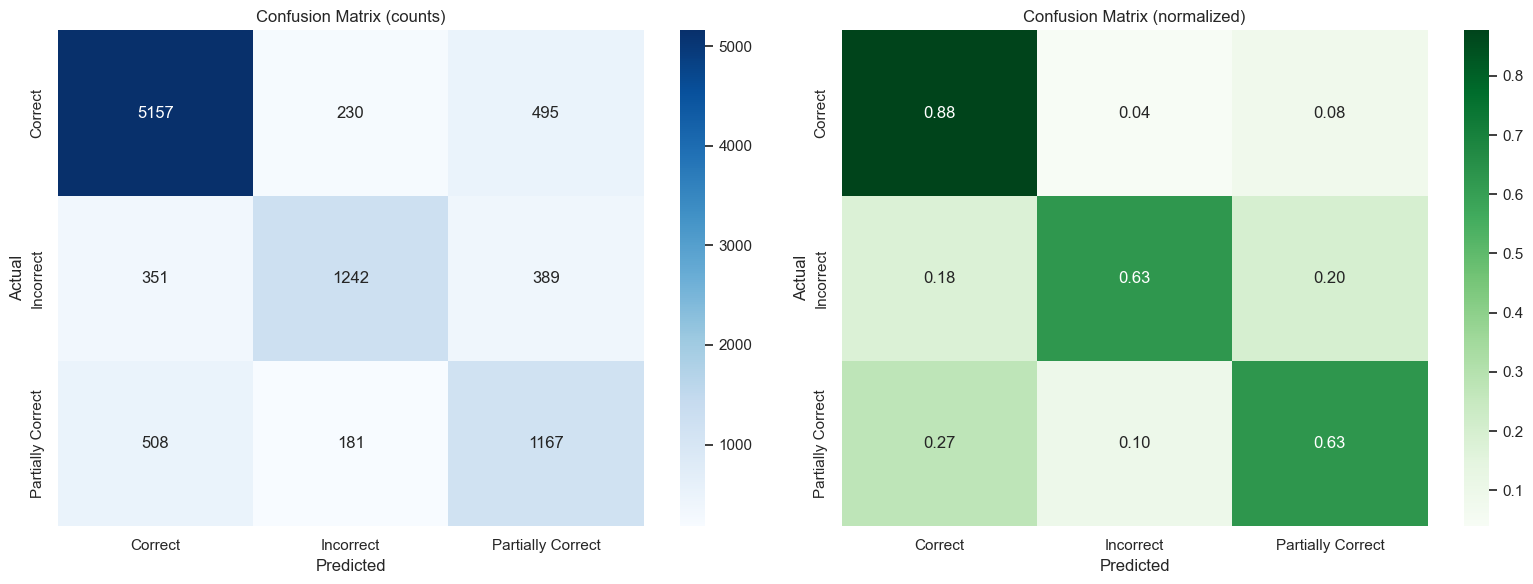

In [16]:
# ============================================================
# CELL 16: Confusion Matrix Visualization
# ============================================================
cm      = confusion_matrix(test_true, test_preds, labels=list(range(NUM_LABELS)))
cm_norm = cm.astype("float") / np.maximum(cm.sum(axis=1, keepdims=True), 1)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=LABELS, yticklabels=LABELS, ax=axes[0])
axes[0].set_title("Confusion Matrix (counts)")
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")

sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Greens",
            xticklabels=LABELS, yticklabels=LABELS, ax=axes[1])
axes[1].set_title("Confusion Matrix (normalized)")
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

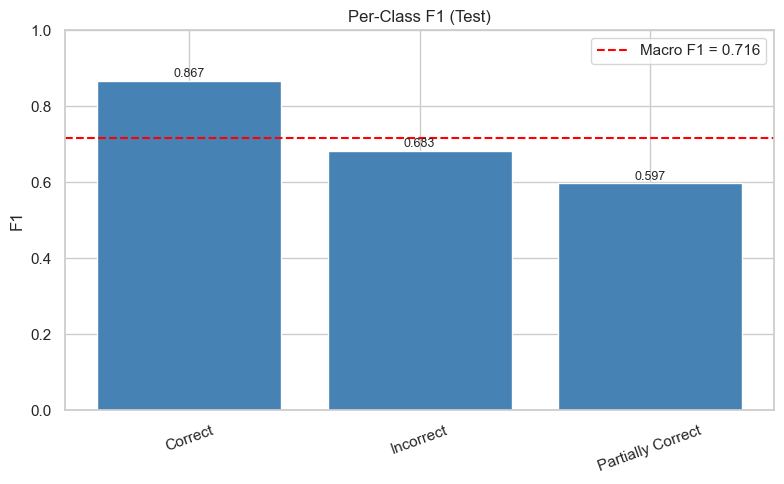

In [17]:
# ============================================================
# CELL 17: Per-Class F1 Bar Chart
# ============================================================
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(per_class["label"], per_class["f1"], color="steelblue")
ax.axhline(test_mf1, color="red", linestyle="--", label=f"Macro F1 = {test_mf1:.3f}")
ax.set_ylim(0, 1); ax.set_ylabel("F1"); ax.set_title("Per-Class F1 (Test)")
ax.tick_params(axis="x", rotation=20)
for b, v in zip(bars, per_class["f1"]):
    ax.text(b.get_x() + b.get_width()/2, v + 0.01, f"{v:.3f}", ha="center", fontsize=9)
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "per_class_f1.png", dpi=300, bbox_inches="tight")
plt.show()

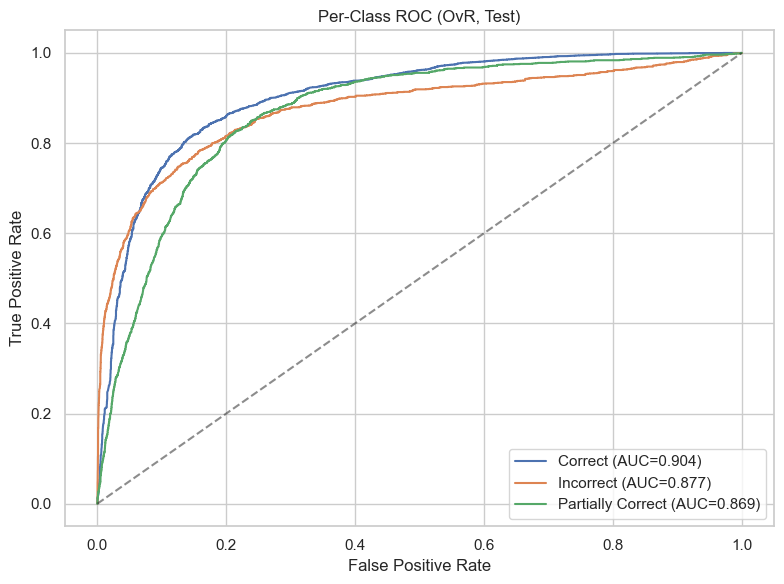

In [18]:
# ============================================================
# CELL 18: ROC Curves (One-vs-Rest)
# ============================================================
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

y_bin = label_binarize(test_true, classes=list(range(NUM_LABELS)))
fig, ax = plt.subplots(figsize=(8, 6))
for i, lbl in enumerate(LABELS):
    if y_bin[:, i].sum() == 0: continue
    fpr, tpr, _ = roc_curve(y_bin[:, i], test_probs[:, i])
    ax.plot(fpr, tpr, label=f"{lbl} (AUC={auc(fpr, tpr):.3f})")
ax.plot([0, 1], [0, 1], "k--", alpha=0.5)
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("Per-Class ROC (OvR, Test)"); ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "roc_curves.png", dpi=300, bbox_inches="tight")
plt.show()

Expected Calibration Error (ECE): 0.1849


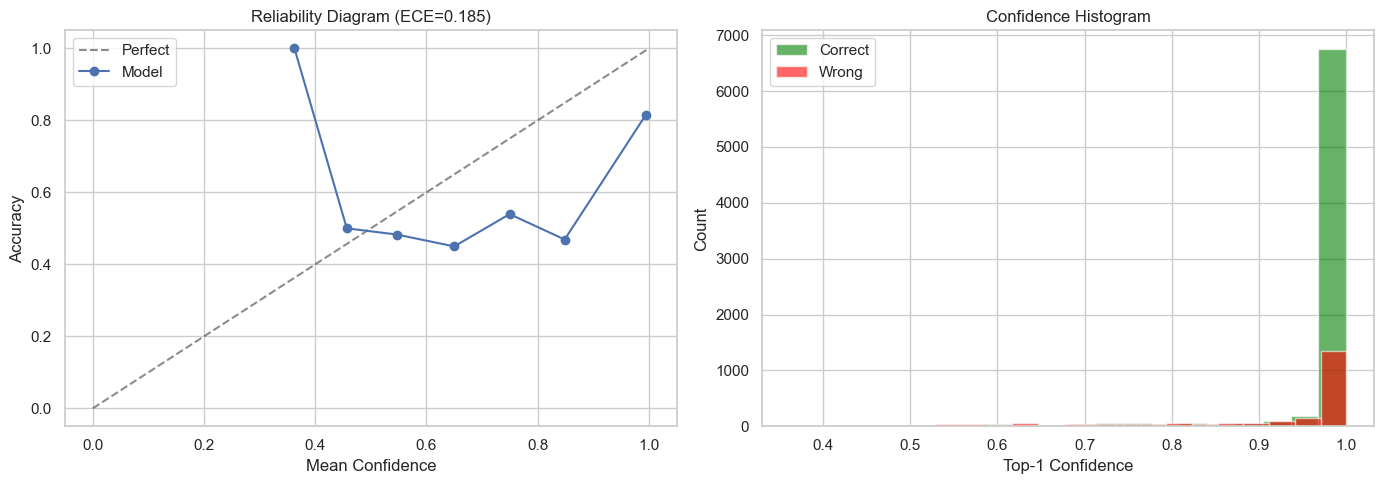

In [19]:
# ============================================================
# CELL 19: Calibration Analysis (ECE + Reliability Diagram)
# ============================================================
confidences = test_probs.max(axis=1)
correct = (test_preds == test_true).astype(int)
n_bins, edges = 10, np.linspace(0, 1, 11)
ece = 0.0
pts = []
for i in range(n_bins):
    m = (confidences >= edges[i]) & (confidences < edges[i+1])
    if m.sum() == 0: continue
    mc, ma = confidences[m].mean(), correct[m].mean()
    ece += m.sum() / len(confidences) * abs(mc - ma)
    pts.append(((edges[i]+edges[i+1])/2, mc, ma))

print(f"Expected Calibration Error (ECE): {ece:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
if pts:
    _, cs, acs = zip(*pts)
    axes[0].plot([0,1], [0,1], "k--", alpha=0.5, label="Perfect")
    axes[0].plot(cs, acs, "o-", label="Model")
    axes[0].set_xlabel("Mean Confidence"); axes[0].set_ylabel("Accuracy")
    axes[0].set_title(f"Reliability Diagram (ECE={ece:.3f})"); axes[0].legend()

axes[1].hist(confidences[correct==1], bins=20, alpha=0.6, color="green", label="Correct")
axes[1].hist(confidences[correct==0], bins=20, alpha=0.6, color="red",   label="Wrong")
axes[1].set_xlabel("Top-1 Confidence"); axes[1].set_ylabel("Count")
axes[1].set_title("Confidence Histogram"); axes[1].legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "calibration.png", dpi=300, bbox_inches="tight")
plt.show()

  language  samples  accuracy  macro_f1  weighted_f1  cohen_kappa
0       EN     1614    0.7912    0.7187       0.7897       0.6020
1       HI     1626    0.7866    0.6937       0.7856       0.5706
2    HI-EN     1620    0.7753    0.7463       0.7750       0.6300
3       NE     1626    0.7761    0.7208       0.7757       0.6080
4       TA     1620    0.7821    0.6954       0.7787       0.5845
5       TE     1614    0.7590    0.6865       0.7614       0.5603


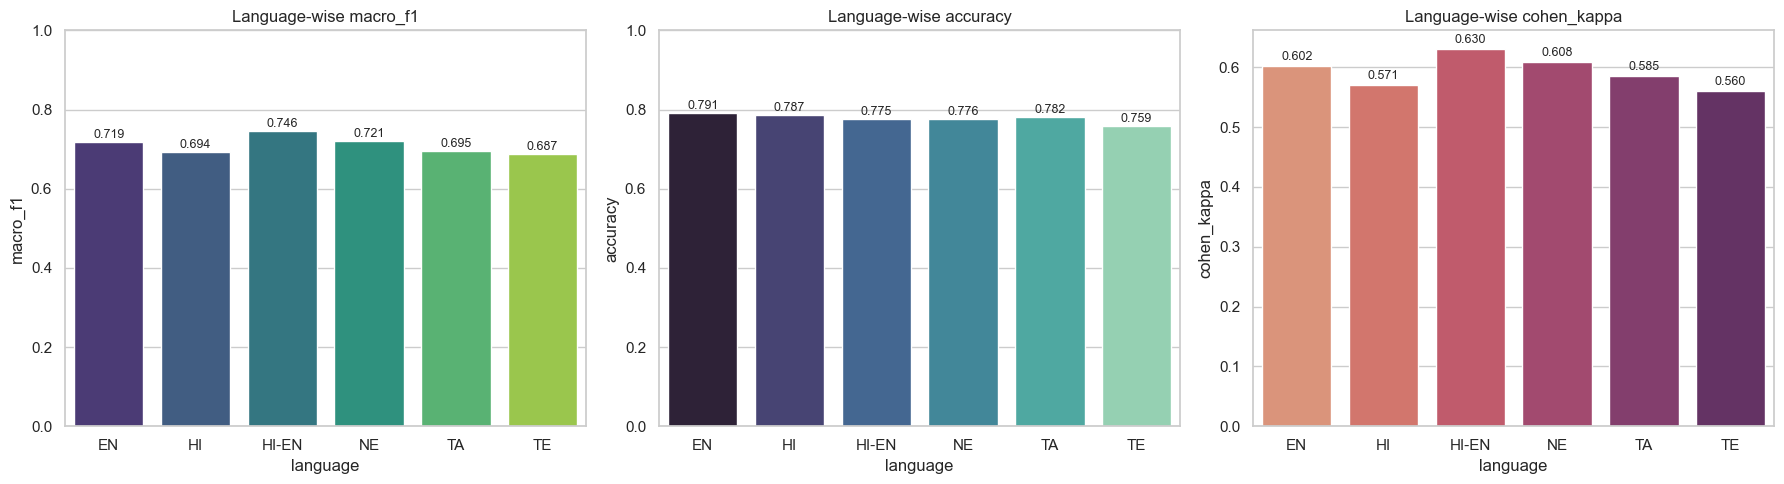

In [20]:
# ============================================================
# CELL 20: Language-Wise Metrics
# ============================================================
def grouped_metrics(df, group_col):
    rows = []
    for g in sorted(df[group_col].dropna().unique()):
        mask = df[group_col].to_numpy() == g
        yt, yp = test_true[mask], test_preds[mask]
        if len(yt) == 0: continue
        rows.append({
            group_col: g, "samples": int(mask.sum()),
            "accuracy": accuracy_score(yt, yp),
            "macro_f1": f1_score(yt, yp, labels=list(range(NUM_LABELS)),
                                 average="macro", zero_division=0),
            "weighted_f1": f1_score(yt, yp, labels=list(range(NUM_LABELS)),
                                    average="weighted", zero_division=0),
            "cohen_kappa": cohen_kappa_score(yt, yp),
        })
    return pd.DataFrame(rows)

lang_df = grouped_metrics(test_df, "language")
print(lang_df.round(4))
lang_df.to_csv(OUTPUT_DIR / "language_wise_results.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col, cmap in zip(axes, ["macro_f1", "accuracy", "cohen_kappa"],
                        ["viridis", "mako", "flare"]):
    sns.barplot(data=lang_df, x="language", y=col, ax=ax, palette=cmap)
    ax.set_title(f"Language-wise {col}")
    if col != "cohen_kappa": ax.set_ylim(0, 1)
    for i, v in enumerate(lang_df[col]):
        ax.text(i, v + 0.01, f"{v:.3f}", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "language_wise.png", dpi=300, bbox_inches="tight")
plt.show()

In [21]:
# ============================================================
# CELL 21: Domain / Difficulty / Fact-Type Wise Metrics
# ============================================================
for col in ["domain_ref", "difficulty_ref", "fact_type_resp"]:
    if col in test_df.columns:
        df_g = grouped_metrics(test_df, col)
        print(f"\n{col}:")
        print(df_g.round(4))
        df_g.to_csv(OUTPUT_DIR / f"{col}_wise_results.csv", index=False)

In [22]:
# ============================================================
# CELL 22: Save Predictions, Metrics, and Splits
# ============================================================
pred_df = test_df[[
    "response_id", "question_id", "language", "model_name",
    "correctness_label", "question", "ground_truth", "response",
]].copy()
pred_df["predicted_label"] = label_encoder.inverse_transform(test_preds)
pred_df["confidence"] = test_probs.max(axis=1)
pred_df["correct_prediction"] = (
    pred_df["correctness_label"] == pred_df["predicted_label"]
)
for i, lbl in enumerate(LABELS):
    pred_df[f"prob_{lbl}"] = test_probs[:, i]

pred_df.to_csv(OUTPUT_DIR / "test_predictions_full.csv", index=False)
pred_df[~pred_df["correct_prediction"]].to_csv(
    OUTPUT_DIR / "test_errors.csv", index=False
)

metrics_output = {
    "model": MODEL_NAME, "task": "Four-class correctness classification",
    "train_rows": len(train_df), "dev_rows": len(dev_df), "test_rows": len(test_df),
    "labels": LABELS, "seed": SEED,
    "test_metrics": {
        "accuracy": float(test_acc),
        "macro_f1": float(test_mf1),
        "weighted_f1": float(test_wf1),
        "cohen_kappa": float(test_kap),
        "mcc": float(test_mcc),
        "roc_auc_macro": float(test_auc) if not np.isnan(test_auc) else None,
        "log_loss": float(test_ll) if not np.isnan(test_ll) else None,
        "top2_accuracy": float(test_top2) if not np.isnan(test_top2) else None,
        "ece": float(ece),
    },
    "per_class": per_class.to_dict(orient="records"),
}
with open(OUTPUT_DIR / "test_metrics_full.json", "w", encoding="utf-8") as f:
    json.dump(metrics_output, f, indent=4)

train_df.to_csv(OUTPUT_DIR / "train_split.csv", index=False)
dev_df.to_csv(OUTPUT_DIR / "dev_split.csv", index=False)
test_df.to_csv(OUTPUT_DIR / "test_split.csv", index=False)

print("\nAll artifacts saved to:", OUTPUT_DIR)


All artifacts saved to: C:\Users\CH.SC.U4CSE23160\Neural Project\IndicHallbench-Hallucinations-Benchmark\results\mbert_full_dataset
